# Shako Lake – Markov Chain Change Analysis (Sentinel-2)

Uses the classified Sentinel-2 maps (9 dates, 14 Nov – 24 Dec 2025) to build a Markov chain model of class change: transition matrices, validation, forecast and change map.

**Run the cells in order.** Choose which model's maps to use with `MODEL` in Cell 1. Results are saved in `Data/Shako/Markov/Sentinel2/<model>/` and overwritten on every run.

## Setup

In [1]:
# === SETUP (run this cell first) – works in Google Colab and on your laptop ===
import os, sys, subprocess

try:
    import google.colab                      # only exists in Colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rasterio"], check=False)

    PROJECT_DIR = "/content/drive/MyDrive/CTECH/Research/proposal/NIDM/GLOF project"   # folder that contains "Data"

    if not os.path.isdir(os.path.join(PROJECT_DIR, "Data")):
        print(f"Not found: {PROJECT_DIR}\nSearching My Drive ...")
        found = []
        top = "/content/drive/MyDrive"
        top_depth = top.count("/")
        for root, dirs, _ in os.walk(top):
            if "Data" in dirs and any(os.path.isdir(os.path.join(root, "Data", s)) for s in ("Shako", "Subu")):
                found.append(root); dirs[:] = []; continue
            if root.count("/") - top_depth >= 8:
                dirs[:] = []
        if not found:
            raise FileNotFoundError("Could not find a folder with Data/Shako in My Drive")
        PROJECT_DIR = found[0]
    BASE_DIR = PROJECT_DIR
else:
    # laptop: walk up from the notebook's folder until a folder containing "Data" is found
    BASE_DIR = os.getcwd()
    while not os.path.isdir(os.path.join(BASE_DIR, "Data")):
        parent = os.path.dirname(BASE_DIR)
        if parent == BASE_DIR:
            raise FileNotFoundError("Could not find a 'Data' folder above the current directory - "
                                    "keep this notebook inside the GLOF project folder")
        BASE_DIR = parent

os.chdir(BASE_DIR)
print("Working in:", BASE_DIR)


Working in: c:\Users\hp\Downloads\CTECH\Research\proposal\NIDM\GLOF project


## Cell 1 – Class areas and transition matrices

Decision Tree maps: 9 dates (2025-11-14 → 2025-12-24), 591 x 490 pixels
Days between dates: [5]  → one Markov step = 5 days
Pixels with data on all dates: 289,551 of 289,590
Pixel size ≈ 9.4 m

Class area (km²):
            Glacier  Glacial Lake  Non-Glacier Land
Date                                               
2025-11-14    9.929         0.567            15.020
2025-11-19    9.036         0.541            15.940
2025-11-24    8.577         0.557            16.382
2025-11-29    8.147         0.538            16.831
2025-12-04    7.691         0.554            17.272
2025-12-09    7.254         0.539            17.724
2025-12-14    7.190         0.260            18.067
2025-12-19    6.752         0.533            18.232
2025-12-24    6.524         0.541            18.451


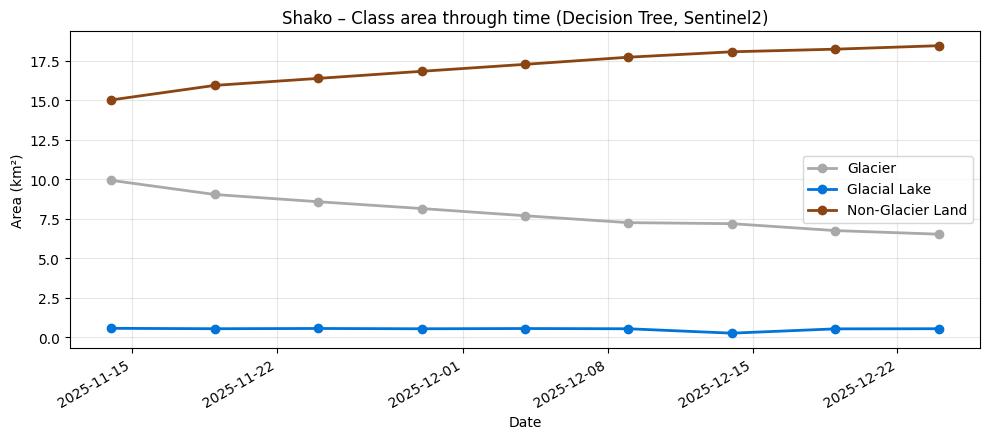

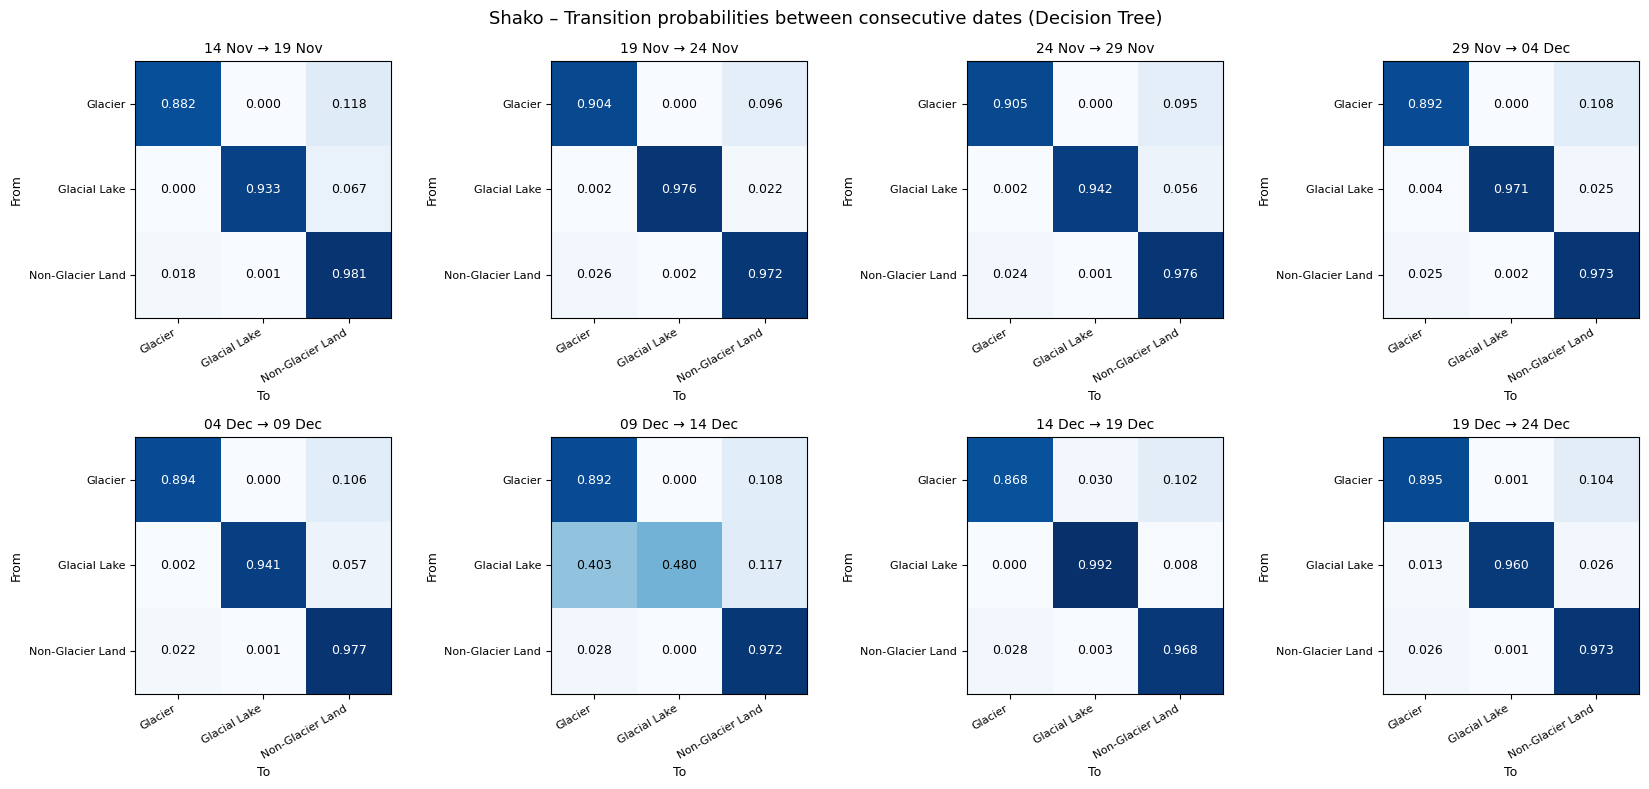


Area moving between classes, 2025-11-14 → 2025-12-24 (km²):
                       To Glacier  To Glacial Lake  To Non-Glacier Land
From Glacier                6.312            0.002                3.615
From Glacial Lake           0.012            0.525                0.030
From Non-Glacier Land       0.201            0.014               14.806


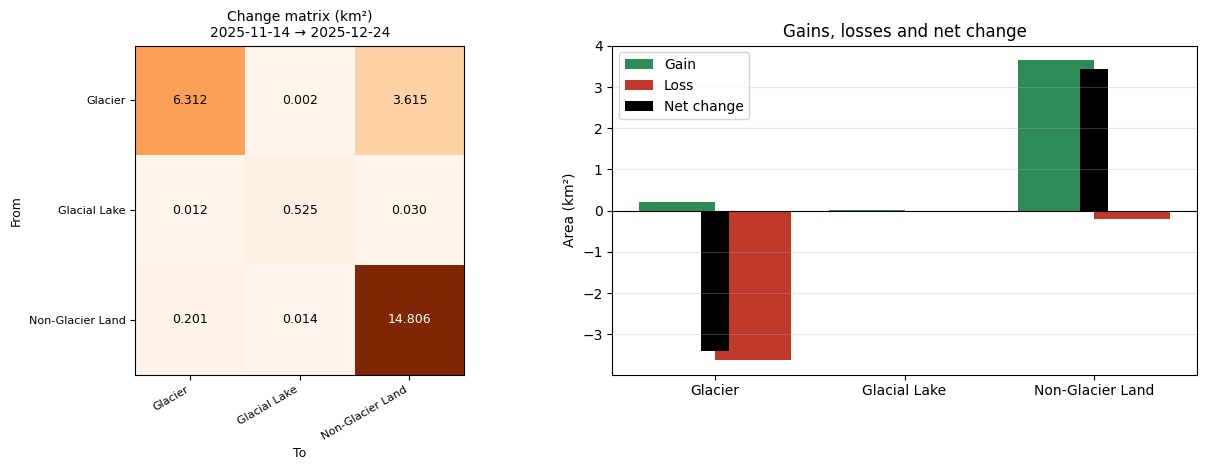


✅ Cell 1 done – results in c:\Users\hp\Downloads\CTECH\Research\proposal\NIDM\GLOF project\Data\Shako\Markov\Sentinel2\decision_tree


In [2]:
import os
import re
import glob
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

# ---------------------------------------------------
# PROJECT ROOT (BASE_DIR from cell 1; found here if not defined)
# ---------------------------------------------------
try:
    BASE_DIR
except NameError:
    BASE_DIR = os.getcwd()
    while not os.path.isdir(os.path.join(BASE_DIR, "Data")):
        parent = os.path.dirname(BASE_DIR)
        if parent == BASE_DIR:
            raise FileNotFoundError("Could not find a 'Data' folder above the current directory")
        BASE_DIR = parent

# =====================================================
# MARKOV CHAIN – CELL 1 : CLASS AREAS + TRANSITION MATRICES
# =====================================================
SITE   = "Shako"
SENSOR = "Sentinel2"

# which classified maps to use:
# "decision_tree", "random_forest", "xgboost", "ann", "cnn", "resnet"
MODEL = "decision_tree"

maps_base = os.path.join(BASE_DIR, "Data", SITE, "Data sample", SENSOR,
                         "Sample Levels", "Spectral", "models", "output")
maps_dir  = maps_base if MODEL == "decision_tree" else os.path.join(maps_base, MODEL)
MODEL_TITLE = {"decision_tree": "Decision Tree", "random_forest": "Random Forest", "xgboost": "XGBoost",
               "ann": "ANN", "cnn": "CNN", "resnet": "ResNet"}[MODEL]

markov_dir = os.path.join(BASE_DIR, "Data", SITE, "Markov", SENSOR, MODEL)
os.makedirs(markov_dir, exist_ok=True)               # every file below is overwritten on each run

# class codes in the classified maps (0 = no data)
CLASSES = {1: "Glacier", 2: "Glacial Lake", 3: "Non-Glacier Land"}
COLORS  = {1: "#A9A9A9", 2: "#0074D9", 3: "#8B4513"}
codes   = list(CLASSES)
names   = [CLASSES[c] for c in codes]
K       = len(codes)

def extract_date(filename):
    m = re.search(r"\d{4}-\d{2}-\d{2}", filename)
    return m.group(0) if m else None

# -------------------------------------------------
# 1. Read all classified maps (sorted by date)
# -------------------------------------------------
files = sorted((f for f in glob.glob(os.path.join(maps_dir, "*.tif")) if extract_date(os.path.basename(f))),
               key=lambda f: extract_date(os.path.basename(f)))
if len(files) < 3:
    raise FileNotFoundError(f"Need at least 3 classified maps in {maps_dir}, found {len(files)}")

dates = pd.to_datetime([extract_date(os.path.basename(f)) for f in files])
stack = []
for f in files:
    with rasterio.open(f) as src:
        stack.append(src.read(1))
        transform, crs, profile = src.transform, src.crs, src.profile
stack = np.stack(stack)                                    # (dates, rows, cols)
T, H, W = stack.shape

step_days = np.diff(dates).astype("timedelta64[D]").astype(int)
STEP = int(np.median(step_days))
print(f"{MODEL_TITLE} maps: {T} dates ({dates[0].date()} → {dates[-1].date()}), {H} x {W} pixels")
print(f"Days between dates: {sorted(set(step_days.tolist()))}  → one Markov step = {STEP} days")

# only pixels that have a class on EVERY date (same pixels compared through time)
valid = np.all(np.isin(stack, codes), axis=0)
print(f"Pixels with data on all dates: {valid.sum():,} of {H*W:,}")

# -------------------------------------------------
# 2. Pixel area (km²) – exact for lat/lon grids, simple for projected grids
# -------------------------------------------------
if crs is not None and crs.is_geographic:
    R = 6371008.8
    lat_edges = transform.f + transform.e * np.arange(H + 1)
    row_area = (R ** 2) * np.radians(abs(transform.a)) * np.abs(
        np.sin(np.radians(lat_edges[:-1])) - np.sin(np.radians(lat_edges[1:])))
    pix_km2 = np.repeat(row_area[:, None] / 1e6, W, axis=1)
else:
    pix_km2 = np.full((H, W), abs(transform.a * transform.e) / 1e6)
print(f"Pixel size ≈ {np.sqrt(pix_km2.mean()) * 1000:.1f} m")

# -------------------------------------------------
# 3. Class area for every date
# -------------------------------------------------
area = pd.DataFrame({CLASSES[c]: [pix_km2[valid & (stack[t] == c)].sum() for t in range(T)] for c in codes},
                    index=dates.date)
area.index.name = "Date"
share = area.div(area.sum(axis=1), axis=0)                # proportion of the study area
area.round(4).to_csv(os.path.join(markov_dir, f"{SITE}_{MODEL}_class_area_km2.csv"))
print("\nClass area (km²):")
print(area.round(3).to_string())

fig, ax = plt.subplots(figsize=(10, 4.5))
for c in codes:
    ax.plot(area.index, area[CLASSES[c]], marker="o", color=COLORS[c], lw=2, label=CLASSES[c])
ax.set_title(f"{SITE} – Class area through time ({MODEL_TITLE}, {SENSOR})")
ax.set_ylabel("Area (km²)"); ax.set_xlabel("Date"); ax.grid(alpha=0.3); ax.legend()
fig.autofmt_xdate(); plt.tight_layout()
fig.savefig(os.path.join(markov_dir, f"{SITE}_{MODEL}_class_area.png"), dpi=300); plt.show()

# -------------------------------------------------
# 4. Transition matrices between consecutive dates
#    counts[i, j] = pixels that were class i and became class j
#    P[i, j]      = counts[i, j] / (all pixels that were class i)  -> each row sums to 1
# -------------------------------------------------
def transition_counts(a, b):
    m = np.zeros((K, K))
    for i, ci in enumerate(codes):
        for j, cj in enumerate(codes):
            m[i, j] = np.sum(valid & (a == ci) & (b == cj))
    return m

def to_prob(m):
    s = m.sum(axis=1, keepdims=True)
    return np.divide(m, s, out=np.zeros_like(m), where=s > 0)

pair_counts = [transition_counts(stack[t], stack[t + 1]) for t in range(T - 1)]
pair_probs  = [to_prob(m) for m in pair_counts]
pair_labels = [f"{dates[t].strftime('%d %b')} → {dates[t+1].strftime('%d %b')}" for t in range(T - 1)]

rows_out = []
for lab, P_t in zip(pair_labels, pair_probs):
    for i in range(K):
        rows_out.append({"Period": lab, "From": names[i], **{f"To {names[j]}": round(P_t[i, j], 4) for j in range(K)}})
pd.DataFrame(rows_out).to_csv(os.path.join(markov_dir, f"{SITE}_{MODEL}_transition_probabilities_by_period.csv"), index=False)

def draw_matrix(ax, M, title, fmt="{:.3f}", cmap="Blues", vmax=1):
    ax.imshow(M, cmap=cmap, vmin=0, vmax=vmax)
    for i in range(K):
        for j in range(K):
            ax.text(j, i, fmt.format(M[i, j]), ha="center", va="center", fontsize=9,
                    color="white" if M[i, j] > 0.6 * vmax else "black")
    ax.set_xticks(range(K)); ax.set_xticklabels(names, rotation=30, ha="right", fontsize=8)
    ax.set_yticks(range(K)); ax.set_yticklabels(names, fontsize=8)
    ax.set_xlabel("To", fontsize=9); ax.set_ylabel("From", fontsize=9)
    ax.set_title(title, fontsize=10)

ncol = 4
nrow = int(np.ceil((T - 1) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4.2 * ncol, 4.0 * nrow), squeeze=False)
for k, ax in enumerate(axes.flat):
    if k < T - 1:
        draw_matrix(ax, pair_probs[k], pair_labels[k])
    else:
        ax.axis("off")
fig.suptitle(f"{SITE} – Transition probabilities between consecutive dates ({MODEL_TITLE})", fontsize=13)
plt.tight_layout()
fig.savefig(os.path.join(markov_dir, f"{SITE}_{MODEL}_transition_matrices_by_period.png"), dpi=300); plt.show()

# -------------------------------------------------
# 5. Whole period: first date -> last date (area in km² moving between classes)
# -------------------------------------------------
cross_km2 = np.zeros((K, K))
for i, ci in enumerate(codes):
    for j, cj in enumerate(codes):
        cross_km2[i, j] = pix_km2[valid & (stack[0] == ci) & (stack[-1] == cj)].sum()
cross_df = pd.DataFrame(cross_km2, index=[f"From {n}" for n in names], columns=[f"To {n}" for n in names])
cross_df.round(4).to_csv(os.path.join(markov_dir, f"{SITE}_{MODEL}_change_matrix_first_to_last_km2.csv"))
print(f"\nArea moving between classes, {dates[0].date()} → {dates[-1].date()} (km²):")
print(cross_df.round(3).to_string())

gain = cross_km2.sum(axis=0) - np.diag(cross_km2)
loss = cross_km2.sum(axis=1) - np.diag(cross_km2)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8))
draw_matrix(a1, cross_km2, f"Change matrix (km²)\n{dates[0].date()} → {dates[-1].date()}",
            fmt="{:.3f}", cmap="Oranges", vmax=cross_km2.max())
x = np.arange(K)
a2.bar(x - 0.2, gain, 0.4, color="#2E8B57", label="Gain")
a2.bar(x + 0.2, -loss, 0.4, color="#C0392B", label="Loss")
a2.bar(x, gain - loss, 0.15, color="black", label="Net change")
a2.axhline(0, color="black", lw=0.8)
a2.set_xticks(x); a2.set_xticklabels(names)
a2.set_ylabel("Area (km²)"); a2.set_title("Gains, losses and net change"); a2.legend(); a2.grid(axis="y", alpha=0.3)
plt.tight_layout()
fig.savefig(os.path.join(markov_dir, f"{SITE}_{MODEL}_change_matrix_gain_loss.png"), dpi=300); plt.show()

print(f"\n✅ Cell 1 done – results in {markov_dir}")


## Cell 2 – Markov model, validation and forecast

Markov transition matrix (one step = 5 days):
                       To Glacier  To Glacial Lake  To Non-Glacier Land
From Glacier               0.8917           0.0035               0.1048
From Glacial Lake          0.0563           0.8935               0.0502
From Non-Glacier Land      0.0248           0.0013               0.9739


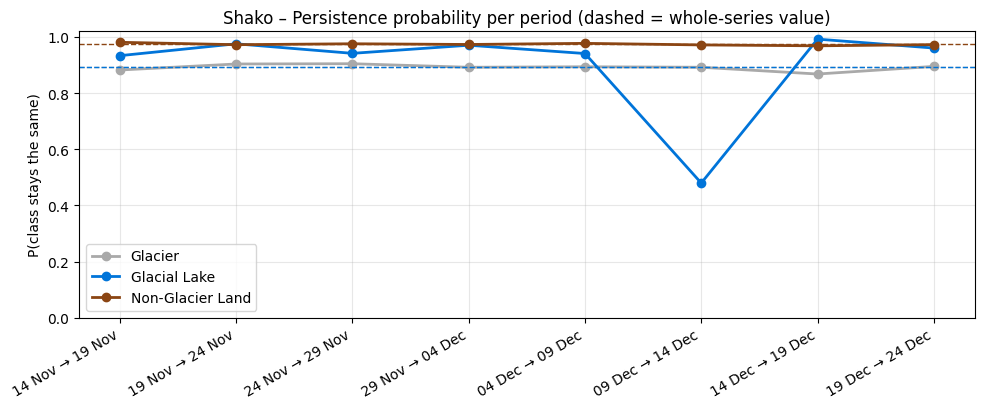


Validation – predict 2025-12-24 from 2025-12-19 (matrix built without the last period):
                  Actual area (km²)  Predicted area (km²)  Error (km²)  Error (%)
Glacier                       6.524                 6.500       -0.024     -0.365
Glacial Lake                  0.541                 0.521       -0.020     -3.697
Non-Glacier Land             18.451                18.495        0.044      0.237
Total absolute error: 0.17 % of the study area

Forecast (km²), next 6 steps of 5 days:
            Glacier  Glacial Lake  Non-Glacier Land
Date                                               
2025-12-29    6.306         0.531            18.680
2026-01-03    6.116         0.522            18.879
2026-01-08    5.951         0.513            19.052
2026-01-13    5.808         0.505            19.203
2026-01-18    5.684         0.498            19.335
2026-01-23    5.576         0.491            19.450

Long-run (steady-state) area if the same change continued:
   Glacier         

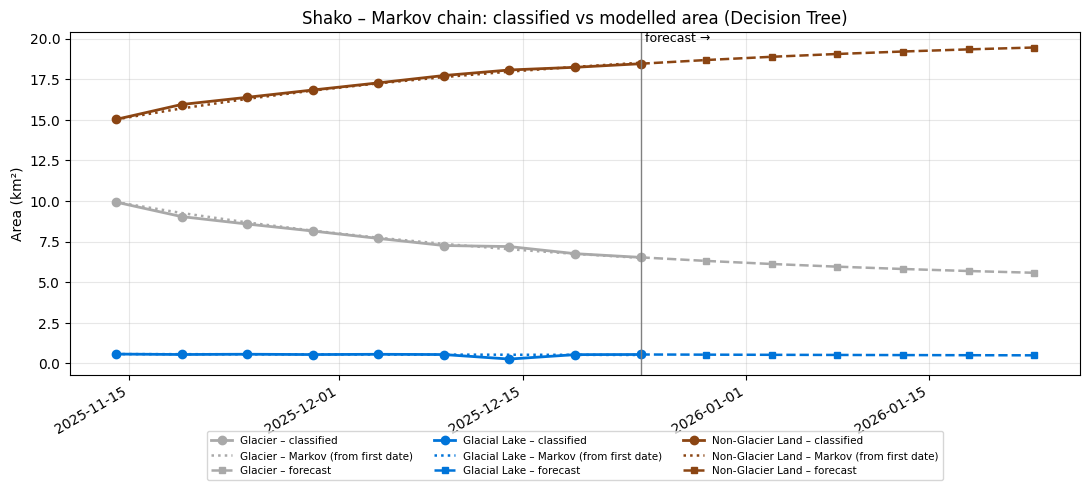

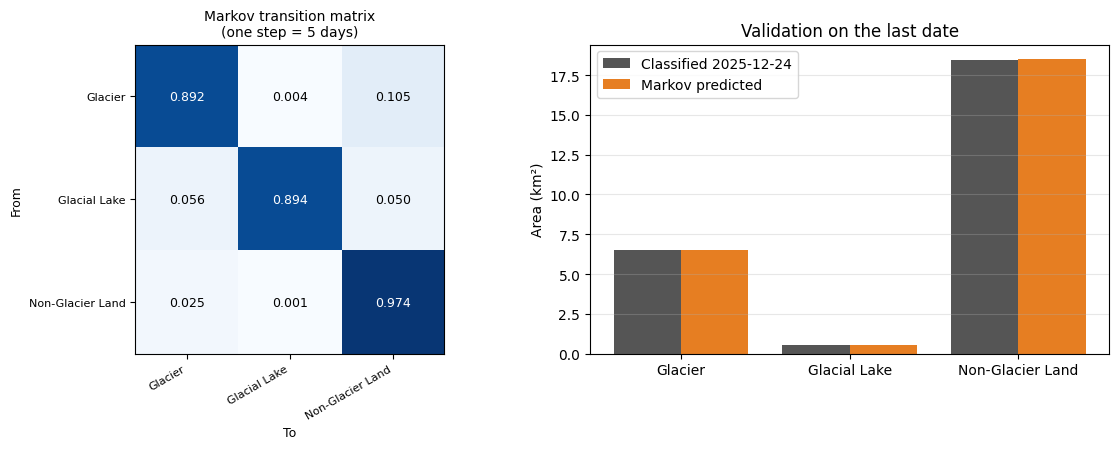


✅ Cell 2 done – results in c:\Users\hp\Downloads\CTECH\Research\proposal\NIDM\GLOF project\Data\Shako\Markov\Sentinel2\decision_tree


In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =====================================================
# MARKOV CHAIN – CELL 2 : MODEL, VALIDATION, FORECAST
# (run Cell 1 first – it reads the maps and builds the transition matrices)
# =====================================================
N_FUTURE = 6          # how many future steps to forecast (each step = STEP days, 5 days for your data)

# -------------------------------------------------
# 1. Markov transition matrix for the whole series
#    (all consecutive pairs pooled together = one average step)
# -------------------------------------------------
P = to_prob(sum(pair_counts))
P_df = pd.DataFrame(P, index=[f"From {n}" for n in names], columns=[f"To {n}" for n in names])
P_df.round(4).to_csv(os.path.join(markov_dir, f"{SITE}_{MODEL}_markov_transition_matrix.csv"))
print(f"Markov transition matrix (one step = {STEP} days):")
print(P_df.round(4).to_string())

# -------------------------------------------------
# 2. Does the chain stay the same through time?  (persistence = probability of keeping the class)
# -------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 4.2))
for i, c in enumerate(codes):
    ax.plot(pair_labels, [Pt[i, i] for Pt in pair_probs], marker="o", lw=2, color=COLORS[c], label=CLASSES[c])
    ax.axhline(P[i, i], color=COLORS[c], ls="--", lw=1)
ax.set_title(f"{SITE} – Persistence probability per period (dashed = whole-series value)")
ax.set_ylabel("P(class stays the same)"); ax.set_ylim(0, 1.02); ax.grid(alpha=0.3); ax.legend()
plt.xticks(rotation=30, ha="right"); plt.tight_layout()
fig.savefig(os.path.join(markov_dir, f"{SITE}_{MODEL}_persistence_by_period.png"), dpi=300); plt.show()

# -------------------------------------------------
# 3. Validation: build the matrix WITHOUT the last period,
#    start from the second-last date and predict the last date
# -------------------------------------------------
P_train = to_prob(sum(pair_counts[:-1]))
start   = share.iloc[-2].to_numpy()
pred    = start @ P_train
actual  = share.iloc[-1].to_numpy()

val = pd.DataFrame({
    "Actual area (km²)":    actual * area.sum(axis=1).iloc[-1],
    "Predicted area (km²)": pred * area.sum(axis=1).iloc[-1],
}, index=names)
val["Error (km²)"] = val["Predicted area (km²)"] - val["Actual area (km²)"]
val["Error (%)"]   = 100 * val["Error (km²)"] / val["Actual area (km²)"].replace(0, np.nan)
val.round(4).to_csv(os.path.join(markov_dir, f"{SITE}_{MODEL}_markov_validation.csv"))
print(f"\nValidation – predict {dates[-1].date()} from {dates[-2].date()} (matrix built without the last period):")
print(val.round(3).to_string())
print(f"Total absolute error: {100 * np.abs(pred - actual).sum() / 2:.2f} % of the study area")

# -------------------------------------------------
# 4. Run the chain from the first date (hindcast) and into the future (forecast)
# -------------------------------------------------
total_km2 = area.sum(axis=1).iloc[-1]
hind = [share.iloc[0].to_numpy()]
for _ in range(T - 1):
    hind.append(hind[-1] @ P)
hind = np.array(hind)

fut = [share.iloc[-1].to_numpy()]
for _ in range(N_FUTURE):
    fut.append(fut[-1] @ P)
fut = np.array(fut)
fut_dates = pd.date_range(dates[-1], periods=N_FUTURE + 1, freq=f"{STEP}D")

forecast = pd.DataFrame(fut[1:] * total_km2, columns=names, index=fut_dates[1:].date)
forecast.index.name = "Date"
forecast.round(4).to_csv(os.path.join(markov_dir, f"{SITE}_{MODEL}_markov_forecast_km2.csv"))
print(f"\nForecast (km²), next {N_FUTURE} steps of {STEP} days:")
print(forecast.round(3).to_string())

# long-run (steady-state) share: the distribution that P no longer changes
w, v = np.linalg.eig(P.T)
ss = np.real(v[:, np.argmin(np.abs(w - 1))]); ss = ss / ss.sum()
print("\nLong-run (steady-state) area if the same change continued:")
for n, s in zip(names, ss):
    print(f"   {n:18s} {s * 100:6.2f} %   ({s * total_km2:.3f} km²)")

fig, ax = plt.subplots(figsize=(11, 5))
for i, c in enumerate(codes):
    ax.plot(dates, share.iloc[:, i] * total_km2, "o-", color=COLORS[c], lw=2, label=f"{CLASSES[c]} – classified")
    ax.plot(dates, hind[:, i] * total_km2, ":", color=COLORS[c], lw=1.8, label=f"{CLASSES[c]} – Markov (from first date)")
    ax.plot(fut_dates, fut[:, i] * total_km2, "s--", color=COLORS[c], lw=1.8, ms=4, label=f"{CLASSES[c]} – forecast")
ax.axvline(dates[-1], color="grey", lw=1); ax.text(dates[-1], ax.get_ylim()[1], " forecast →", va="top", fontsize=9)
ax.set_title(f"{SITE} – Markov chain: classified vs modelled area ({MODEL_TITLE})")
ax.set_ylabel("Area (km²)"); ax.grid(alpha=0.3)
ax.legend(fontsize=7.5, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.15))
fig.autofmt_xdate(); plt.tight_layout()
fig.savefig(os.path.join(markov_dir, f"{SITE}_{MODEL}_markov_hindcast_forecast.png"), dpi=300, bbox_inches="tight"); plt.show()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.6))
draw_matrix(a1, P, f"Markov transition matrix\n(one step = {STEP} days)")
xx = np.arange(K)
a2.bar(xx - 0.2, actual * total_km2, 0.4, color="#555555", label=f"Classified {dates[-1].date()}")
a2.bar(xx + 0.2, pred * total_km2, 0.4, color="#E67E22", label="Markov predicted")
a2.set_xticks(xx); a2.set_xticklabels(names); a2.set_ylabel("Area (km²)")
a2.set_title("Validation on the last date"); a2.legend(); a2.grid(axis="y", alpha=0.3)
plt.tight_layout()
fig.savefig(os.path.join(markov_dir, f"{SITE}_{MODEL}_markov_matrix_validation.png"), dpi=300); plt.show()

print(f"\n✅ Cell 2 done – results in {markov_dir}")


## Cell 3 – Change map (first date → last date)

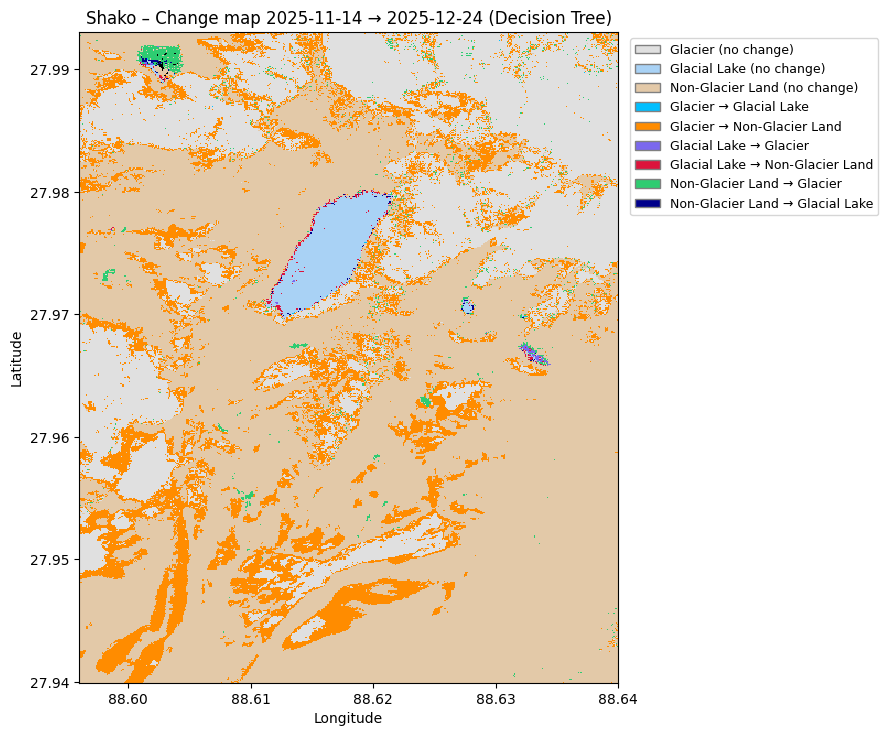

Changed area: 3.874 km² (15.18 % of the study area)
Saved: c:\Users\hp\Downloads\CTECH\Research\proposal\NIDM\GLOF project\Data\Shako\Markov\Sentinel2\decision_tree\Shako_decision_tree_change_map_2025-11-14_to_2025-12-24.tif

✅ All Markov results are in c:\Users\hp\Downloads\CTECH\Research\proposal\NIDM\GLOF project\Data\Shako\Markov\Sentinel2\decision_tree


In [4]:
import os
import glob
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from matplotlib.ticker import FormatStrFormatter, MaxNLocator

# =====================================================
# MARKOV CHAIN – CELL 3 : CHANGE MAP (first date -> last date)
# (run Cell 1 first)
# =====================================================
first, last = stack[0], stack[-1]

# change code = from*10 + to   (e.g. 13 = Glacier -> Non-Glacier Land), 0 = no data
change = np.where(valid, first * 10 + last, 0).astype(np.uint8)

for old in glob.glob(os.path.join(markov_dir, f"{SITE}_{MODEL}_change_map_*.tif")):   # overwrite: remove old change map
    os.remove(old)
out_tif = os.path.join(markov_dir, f"{SITE}_{MODEL}_change_map_{dates[0].date()}_to_{dates[-1].date()}.tif")
prof = profile.copy()
prof.update(dtype=rasterio.uint8, count=1, nodata=0, compress="lzw")
with rasterio.open(out_tif, "w", **prof) as dst:
    dst.write(change, 1)

# categories to show: unchanged classes (pale) + every from->to change that occurs
pale = {1: "#E0E0E0", 2: "#A9D2F5", 3: "#E3C9A8"}
change_colors = {12: "#00BFFF", 13: "#FF8C00", 21: "#7B68EE", 23: "#DC143C", 31: "#2ECC71", 32: "#00008B"}
items = [(0, "No data", "black")]
for c in codes:
    items.append((c * 11, f"{CLASSES[c]} (no change)", pale[c]))
for a in codes:
    for b in codes:
        if a != b and np.any(change == a * 10 + b):
            items.append((a * 10 + b, f"{CLASSES[a]} → {CLASSES[b]}", change_colors.get(a * 10 + b, "#FF00FF")))

lookup = np.zeros(256, dtype=np.uint8)
for k, (code, _, _) in enumerate(items):
    lookup[code] = k
img = lookup[change]
cmap = ListedColormap([col for _, _, col in items])
norm = BoundaryNorm(np.arange(len(items) + 1) - 0.5, cmap.N)

b = rasterio.transform.array_bounds(H, W, transform)      # (west, south, east, north)
fig, ax = plt.subplots(figsize=(9, 9 * H / W + 1))
ax.imshow(img, cmap=cmap, norm=norm, extent=[b[0], b[2], b[1], b[3]], interpolation="nearest")
ax.set_title(f"{SITE} – Change map {dates[0].date()} → {dates[-1].date()} ({MODEL_TITLE})", fontsize=12)
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.xaxis.set_major_formatter(FormatStrFormatter("%.2f")); ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))
ax.xaxis.set_major_locator(MaxNLocator(nbins=5)); ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax.legend(handles=[Patch(facecolor=col, edgecolor="grey", label=lab) for _, lab, col in items[1:]],
          loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9, frameon=True)
plt.tight_layout()
fig.savefig(os.path.join(markov_dir, f"{SITE}_{MODEL}_change_map.png"), dpi=300, bbox_inches="tight"); plt.show()

changed_km2 = pix_km2[valid & (first != last)].sum()
print(f"Changed area: {changed_km2:.3f} km² ({100 * changed_km2 / pix_km2[valid].sum():.2f} % of the study area)")
print("Saved:", out_tif)
print(f"\n✅ All Markov results are in {markov_dir}")
